First look at the amino acid sequence for the Dsup protein of the *Ramazzottius varieornatus* 

In [7]:
from Bio import SeqIO
for seq_record in SeqIO.parse("../data/raw_data/01_dsup_ramva.fasta", "fasta"):
    print(seq_record.id)
    print(repr(seq_record.seq))
    print("amino acids total:", len(seq_record))

P0DOW4:
Seq('MASTHQSSTEPSSTGKSEETKKDASQGSGQDSKNVTVTKGTGSSATSAAIVKTG...KRK')
amino acids total: 445


Counting how many times each amino acid appears in the Dsup

In [2]:
from Bio import SeqIO
from Bio.SeqUtils.ProtParam import ProteinAnalysis
seq_record = SeqIO.read("../data/raw_data/01_dsup_ramva.fasta", "fasta")
analysis = ProteinAnalysis(str(seq_record.seq))
print(analysis.count_amino_acids())

{'A': 72, 'C': 0, 'D': 29, 'E': 19, 'F': 2, 'G': 69, 'H': 5, 'I': 4, 'K': 59, 'L': 1, 'M': 3, 'N': 6, 'P': 14, 'Q': 18, 'R': 12, 'S': 79, 'T': 31, 'V': 21, 'W': 0, 'Y': 1}


all contained amino acids graphed

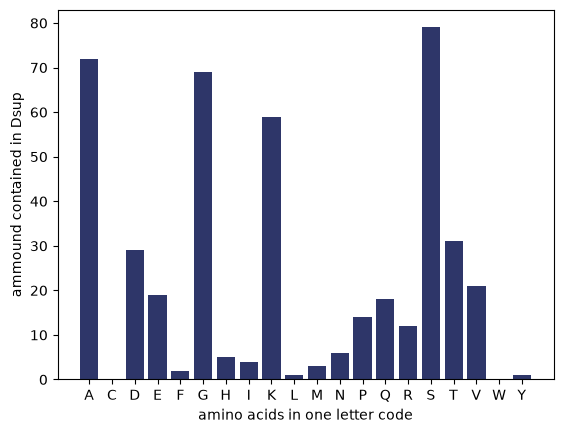

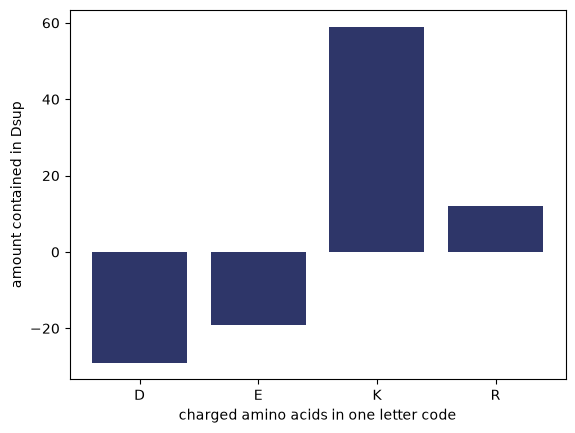

net charge of dsup: 28


In [5]:
import matplotlib.pyplot as plt

all_AS = ["A", "C", "D", "E", "F", "G", "H", "I", "K", "L", "M", "N", "P", "Q", "R", "S", "T", "V", "W", "Y"]
amount_AS = [72, 0, 29, 19, 2, 69, 5, 4, 59, 1, 3, 6, 14, 18, 12, 79, 31, 21, 0, 1]

plt.bar(all_AS, amount_AS, color='#2E3669')
plt.xlabel("amino acids in one letter code")
plt.ylabel("ammound contained in Dsup")
plt.show()

charged_AS = ["D", "E", "K", "R"]
amount_cAS = [-29, -19, 59, 12]

plt.bar(charged_AS, amount_cAS, color='#2E3669')
plt.xlabel("charged amino acids in one letter code")
plt.ylabel("amount contained in Dsup")
plt.show()

netcharge = -29 + (-19) + 5 + 59 + 12  # ignore histidin since its at pH 7 mostly neutral charged?
print("net charge of dsup:", netcharge)

sliding window for charge distribution 

[0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 1, 0, -1, -1, 0, 1, 1, -1, 0, 0, 0, 0, 0, 0, 0, -1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, -1, 0, 1, 0, 0, 0, 0, -1, 0, 1, -1, 1, 0, 1, 0, 0, 0, 1, -1, 0, 0, 0, 0, 0, -1, 0, 1, 0, 0, 0, -1, 0, 1, 0, 0, 0, -1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, -1, 0, 0, 1, 0, 0, 0, -1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, -1, 0, 0, 0, 0, 0, 1, -1, 0, 0, 0, 1, 0, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, -1, 1, 0, -1, -1, 1, 1, -1, 0, -1, 0, 0, 0, -1, 1, 1, -1, -1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 1, 1, 0, -1, 0, -1, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, -1, 0, 0, 1, 0, 0, -1, 0, 0, 0, 0, -1, 0, -1, 0, 0, -1, 0, 0, 0, 1, 0, 0, 0, -

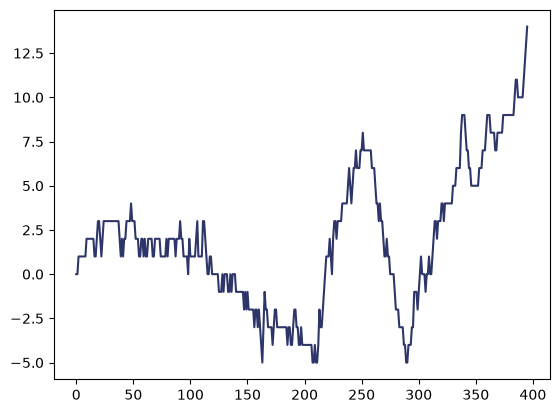

In [7]:
import matplotlib.pyplot as plt
import numpy as np


dsup_sequence = list("MASTHQSSTEPSSTGKSEETKKDASQGSGQDSKNVTVTKGTGSSATSAAIVKTGGSQGKDSSTTAGSSSTQGQKFSTTPTDPKTFSSDQKEKSKSPAKEVPSGGDSKSQGDTKSQSDAKSSGQSQGQSKDSGKSSSDSSKSHSVIGAVKDVVAGAKDVAGKAVEDAPSIMHTAVDAVKNAATTVKDVASSAASTVAEKVVDAYHSVVGDKTDDKKEGEHSGDKKDDSKAGSGSGQGGDNKKSEGETSGQAESSSGNEGAAPAKGRGRGRPPAAAKGVAKGAAKGAAASKGAKSGAESSKGGEQSSGDIEMADASSKGGSDQRDSAATVGEGGASGSEGGAKKGRGRGAGKKADAGDTSAEPPRRSSRLTSSGTGAGSAPAAAKGGAKRAASSSSTPSNAKKQATGGAGKAAATKATAAKSAASKAPQNGAGAKKKGGKAGGRKRK") 
dsup_charge_seq = []

for x in dsup_sequence:
    if x == "R":
        dsup_charge_seq.append(1)
    elif x == "K":
        dsup_charge_seq.append(1)
    elif x == "D":
        dsup_charge_seq.append(-1)
    elif x == "E":
        dsup_charge_seq.append(-1)
    else:
        dsup_charge_seq.append(0)

print(dsup_charge_seq)
print("sequence length:", len(dsup_charge_seq))
print("total positive charge:", dsup_charge_seq.count(1))
print("total negative charge:", dsup_charge_seq.count(-1))
print("total charge:", dsup_charge_seq.count(1) - dsup_charge_seq.count(-1))

window_charge = []
window_size = 50

for x in range(len(dsup_charge_seq) - window_size + 1): 
    window = dsup_charge_seq[x : x + window_size]
    window_charge.append(sum(window))

charge_plotable = np.array(window_charge)

plt.plot(charge_plotable, color='#2E3669')

pLDDT value per residue to show confidence of local structure 

A 445
[54.41, 40.22, 51.97, 41.22, 61.34, 46.06, 58.97, 46.28, 46.06, 51.62, 47.0, 56.84, 49.16, 53.28, 41.28, 55.47, 46.75, 58.5, 41.69, 52.12, 48.41, 44.34, 50.66, 45.97, 46.72, 45.69, 42.06, 44.06, 44.06, 48.88, 45.56, 49.19, 52.53, 51.31, 51.06, 49.16, 55.03, 57.41, 52.03, 40.94, 48.94, 44.75, 42.97, 43.62, 42.59, 43.25, 44.16, 42.44, 45.69, 45.75, 49.91, 44.75, 50.78, 42.53, 41.28, 47.84, 44.09, 43.69, 43.5, 59.56, 45.22, 55.31, 44.28, 43.28, 44.19, 38.19, 40.72, 44.5, 42.19, 44.81, 45.38, 40.78, 47.97, 52.91, 49.03, 43.38, 52.41, 45.78, 52.59, 50.66, 46.09, 59.06, 54.22, 45.34, 46.78, 47.12, 54.47, 47.31, 51.31, 50.22, 52.22, 49.0, 57.44, 49.0, 49.97, 49.19, 47.03, 48.09, 47.78, 52.69, 52.81, 55.59, 43.75, 47.94, 46.75, 57.31, 51.75, 54.22, 51.5, 47.62, 45.22, 53.84, 46.44, 52.06, 46.12, 54.59, 42.78, 47.72, 46.28, 45.31, 48.72, 43.41, 45.09, 50.16, 41.56, 43.12, 41.25, 49.91, 43.66, 44.25, 46.25, 35.62, 42.47, 38.75, 50.53, 46.38, 39.94, 43.81, 41.94, 45.28, 45.09, 50.84, 65.5, 

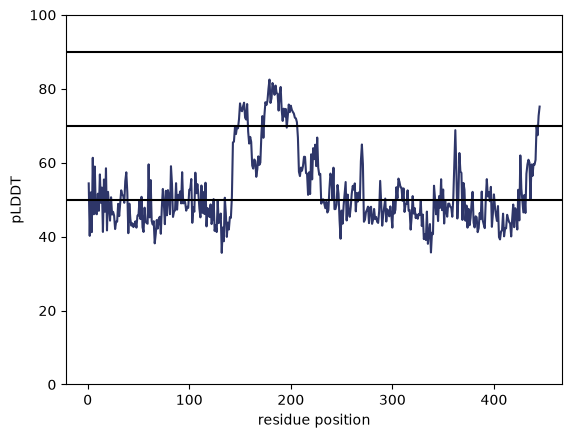

In [12]:
from Bio.PDB import MMCIFParser
import matplotlib.pyplot as plt
import numpy as np

parser = MMCIFParser(QUIET=True)
structure = parser.get_structure("dsup", "../data/raw_data/alfafold_dsup_ramva.cif")

# each amino acid has a value between 0 and 100 assigned to it

for model in structure:
    for chain in model:
        print(chain.id, len(chain))

plddt = []

for residue in chain:
    plddt.append(residue["CA"].get_bfactor()) 

print(plddt)

# checking if the list makes sense, right length and only values betweenn 0 and 100
print(len(plddt))
print(min(plddt))
print(max(plddt))


#plotting
range234 = np.arange(1, 446)
plt.plot(range234, plddt, color='#2E3669')
plt.xlabel("residue position")
plt.ylabel("pLDDT")
plt.axhline(y=50, c='k')
plt.axhline(y=70, c='k')
plt.axhline(y=90, c='k')
plt.ylim(0,100)
plt.show()